In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# load dataset
train_data=pd.read_csv("E:\\ds project\\house-prices\\train.csv")
df1=train_data


# shape
print("Shape of df_train: ",df1.shape)

Shape of df_train:  (1460, 29)


In [3]:
df1

,MSZoning,LotFrontage,LotArea,Alley,LandContour,Neighborhood,BldgType,HouseStyle,OverallCond,YearBuilt,...,Fireplaces,GarageType,GarageYrBlt,GarageCars,PoolArea,PoolQC,Fence,MiscFeature,YrSold,SalePrice
0,RL,65.0,8450,NaN,Lvl,CollgCr,1Fam,2Story,5,2003,...,0,Attchd,2003.0,2,0,NaN,NaN,NaN,2008,208500
1,RL,80.0,9600,NaN,Lvl,Veenker,1Fam,1Story,8,1976,...,1,Attchd,1976.0,2,0,NaN,NaN,NaN,2007,181500
2,RL,68.0,11250,NaN,Lvl,CollgCr,1Fam,2Story,5,2001,...,1,Attchd,2001.0,2,0,NaN,NaN,NaN,2008,223500
3,RL,60.0,9550,NaN,Lvl,Crawfor,1Fam,2Story,5,1915,...,1,Detchd,1998.0,3,0,NaN,NaN,NaN,2006,140000
4,RL,84.0,14260,NaN,Lvl,NoRidge,1Fam,2Story,5,2000,...,1,Attchd,2000.0,3,0,NaN,NaN,NaN,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,NaN,Lvl,Gilbert,1Fam,2Story,5,1999,...,1,Attchd,1999.0,2,0,NaN,NaN,NaN,2007,175000
1456,RL,85.0,13175,NaN,Lvl,NWAmes,1Fam,1Story,6,1978,...,2,Attchd,1978.0,2,0,NaN,MnPrv,NaN,2010,210000
1457,RL,66.0,9042,NaN,Lvl,Crawfor,1Fam,2Story,9,1941,...,2,Attchd,1941.0,1,0,NaN,GdPrv,Shed,2010,266500
1458,RL,68.0,9717,NaN,Lvl,NAmes,1Fam,1Story,6,1950,...,0,Attchd,1950.0,1,0,NaN,NaN,NaN,2010,142125


In [4]:
# Drop columns with too many missing values
drop_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence']
df1.drop(columns=drop_cols, inplace=True)

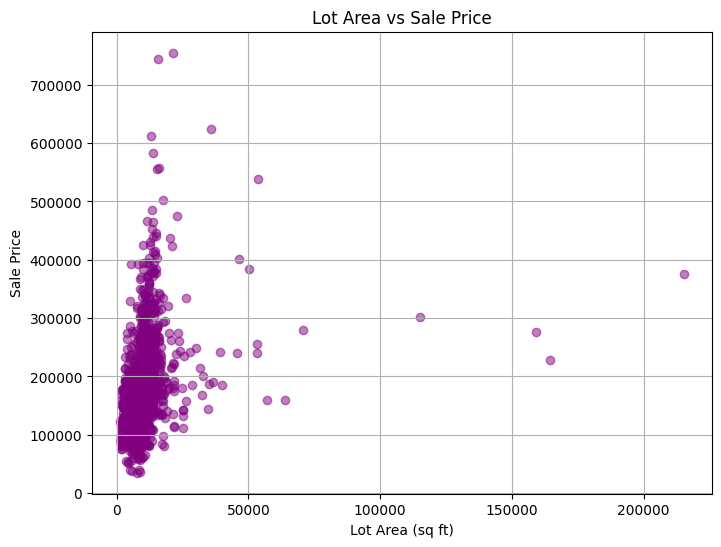

In [5]:
plt.figure(figsize=(8, 6))
plt.scatter(df1['LotArea'], df1['SalePrice'], alpha=0.5, color='purple')
plt.xlabel("Lot Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Lot Area vs Sale Price")
plt.grid(True)
plt.show()

In [6]:
# Function to remove outliers using IQR
def remove_outliers(df1, columns):
    for col in columns:
        Q1 = df1[col].quantile(0.25)
        Q3 = df1[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df1 = df1[(df1[col] >= lower) & (df1[col] <= upper)]
    return df1

#removaling outlier
df1_no_outliers = remove_outliers(df1, ['LotArea','SalePrice'])

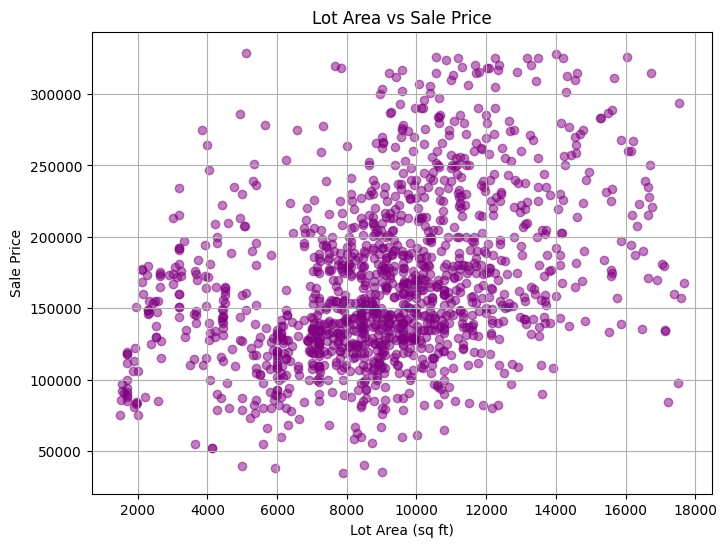

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(df1_no_outliers['LotArea'], df1_no_outliers['SalePrice'], alpha=0.5, color='purple')
plt.xlabel("Lot Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Lot Area vs Sale Price")
plt.grid(True)
plt.show()

In [8]:
#numerical missing values with median
num_cols = ['LotFrontage', 'GarageYrBlt']
for col in num_cols:
    df1.loc[:, col] = df1[col].fillna(df1[col].median())

In [9]:
# categorical missing values with 'None'
df1.loc[:, 'GarageType'] = df1['GarageType'].fillna('None')

In [10]:
#missing value in Electrical with mode
df1.loc[:, 'Electrical'] = df1['Electrical'].fillna(df1['Electrical'].mode()[0])

In [11]:
df1.head()

,MSZoning,LotFrontage,LotArea,LandContour,Neighborhood,BldgType,HouseStyle,OverallCond,YearBuilt,YearRemodAdd,...,HalfBath,BedroomAbvGr,KitchenAbvGr,Fireplaces,GarageType,GarageYrBlt,GarageCars,PoolArea,YrSold,SalePrice
0,RL,65.0,8450,Lvl,CollgCr,1Fam,2Story,5,2003,2003,...,1,3,1,0,Attchd,2003.0,2,0,2008,208500
1,RL,80.0,9600,Lvl,Veenker,1Fam,1Story,8,1976,1976,...,0,3,1,1,Attchd,1976.0,2,0,2007,181500
2,RL,68.0,11250,Lvl,CollgCr,1Fam,2Story,5,2001,2002,...,1,3,1,1,Attchd,2001.0,2,0,2008,223500
3,RL,60.0,9550,Lvl,Crawfor,1Fam,2Story,5,1915,1970,...,0,3,1,1,Detchd,1998.0,3,0,2006,140000
4,RL,84.0,14260,Lvl,NoRidge,1Fam,2Story,5,2000,2000,...,1,4,1,1,Attchd,2000.0,3,0,2008,250000


In [12]:
#Encode Categorical Variables using One-Hot Encoding
df1_encoded = pd.get_dummies(df1, drop_first=True)

In [13]:
X = df1_encoded.drop("SalePrice", axis=1)
y = df1_encoded["SalePrice"]

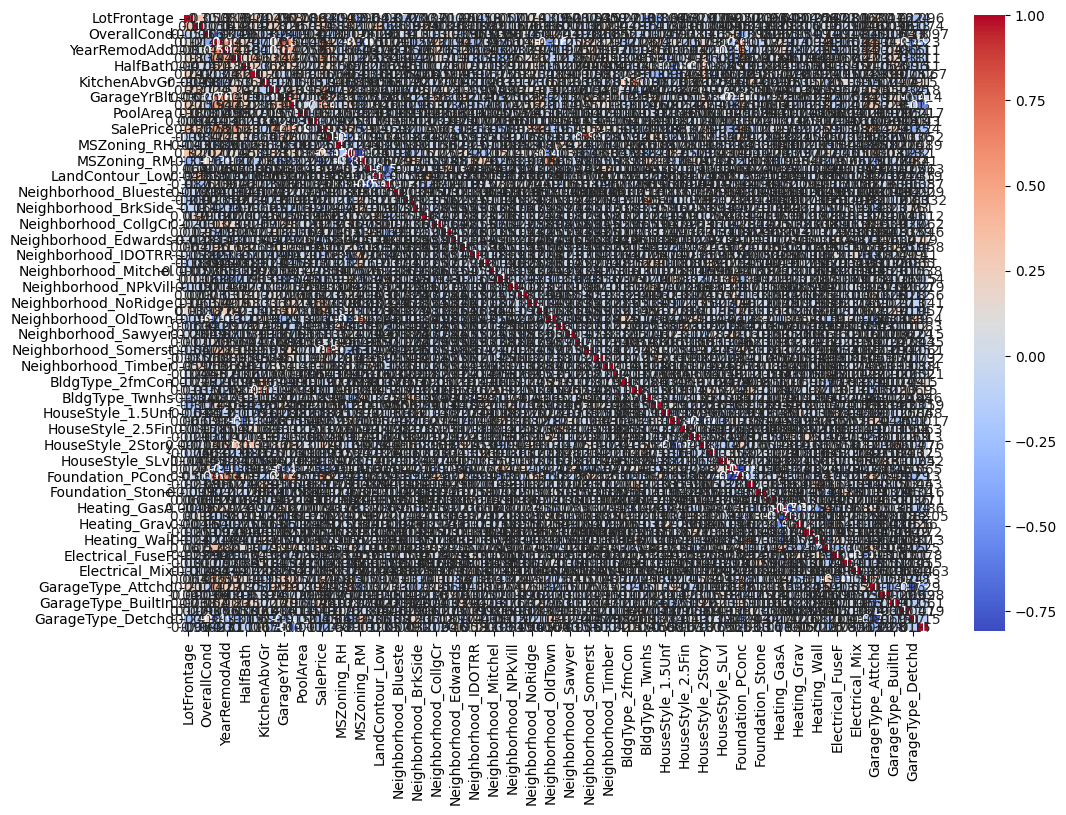

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df1_encoded.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

In [15]:
# Split into train/test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 80% train, 20% test

In [16]:
pd.DataFrame({'feature_names': X_train.columns.tolist()}).to_csv("training_features.csv", index=False)

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)    

In [18]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)
xgb_model.fit(X_train_scaled, y_train)

y_pred_xgb = xgb_model.predict(X_test_scaled)

In [20]:
from sklearn.metrics import r2_score
print("R² Score (XGBoost):", r2_score(y_test, y_pred_xgb))

R² Score (XGBoost): 0.8472462296485901


In [21]:
import joblib

joblib.dump(xgb_model, "house_price_model.pkl")


['house_price_model.pkl']

In [22]:
import joblib
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [23]:
import os
os.getcwd()

'e:\\ds project\\backend'

In [24]:
y_pred = xgb_model.predict(X_test_scaled)
print("Predictions on test data:", y_pred[:5])  # Show first 5 predictions

Predictions on test data: [135031.58 299663.16 130661.66 151655.27 359231.38]


In [25]:
for actual, predicted in zip(y_test[:5], y_pred[:5]):
    print(f"Actual: {actual}, Predicted: {predicted}")

Actual: 154500, Predicted: 135031.578125
Actual: 325000, Predicted: 299663.15625
Actual: 115000, Predicted: 130661.65625
Actual: 159000, Predicted: 151655.265625
Actual: 315500, Predicted: 359231.375
